# Mean-variance portfolios on the 49 Fama-French industries

Long-only minimum variance and optimal portfolios (2, 3, 5 and 10-year lookbacks, monthly rebalancing) against equal weighting and the CRSP market, Jan 1980 – Sep 2026. See `README.md`.

In [1]:
from pathlib import Path

from src.backtest import run_backtest
from src.data import load_data
from src.metrics import performance_table
from src.plots import plot_frontier, plot_wealth

TABLES = Path("output/tables")
FIGURES = Path("output/figures")
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

## Data

In [2]:
daily, monthly, market, rf, rebalance_dates = load_data()

for name, df in {"Daily industries": daily, "Monthly industries": monthly, "Market": market, "Risk-free": rf}.items():
    print(f"{name:<20}{str(df.index[0])[:10]} – {str(df.index[-1])[:10]}  {df.shape}")

Daily industries    1970-01-02 – 2026-09-30  (14308, 49)
Monthly industries  1970-01 – 2026-09  (681, 49)
Market              1970-01 – 2026-09  (681,)
Risk-free           1970-01 – 2026-09  (681,)


## Backtest

In [3]:
returns, weights = run_backtest(daily, monthly, market, rf, rebalance_dates)
returns.head()

,MinVar 2y,MinVar 3y,MinVar 5y,MinVar 10y,Optimal 2y,Optimal 3y,Optimal 5y,Optimal 10y,1/N,Market
1980-01,0.020621,0.020293,0.021535,0.024287,0.129416,0.114613,0.098440,0.125209,0.069865,0.0630
1980-02,-0.020304,-0.019792,-0.020337,-0.021249,0.032340,0.006335,-0.021589,0.048639,-0.029335,-0.0034
1980-03,-0.071194,-0.071798,-0.074924,-0.077649,-0.193044,-0.158335,-0.149617,-0.194579,-0.118916,-0.1169
1980-04,0.101241,0.101966,0.104667,0.105519,0.083559,0.109040,0.058761,0.048068,0.043512,0.0521
1980-05,0.050732,0.050929,0.051321,0.053415,0.058810,0.052389,0.048052,0.056337,0.069671,0.0607


## Performance

In [4]:
performance = performance_table(returns, rf, market)

pct, dec2 = "{:.2%}", "{:.2f}"
performance.style.format({
    "CAGR": pct, "Volatility": pct, "Sharpe": dec2, "Max drawdown": pct,
    "Alpha": pct, "Alpha p-value": "{:.3f}", "Beta": dec2,
}, na_rep="–")

,CAGR,Volatility,Sharpe,Max drawdown,Alpha,Alpha p-value,Beta
MinVar 2y,11.49%,12.12%,0.64,-36.94%,2.53%,0.034,0.59
MinVar 3y,11.80%,12.14%,0.66,-35.28%,2.84%,0.018,0.58
MinVar 5y,11.17%,12.03%,0.62,-34.36%,2.30%,0.054,0.58
MinVar 10y,11.38%,12.27%,0.62,-44.21%,2.50%,0.044,0.58
Optimal 2y,13.36%,18.68%,0.56,-51.45%,2.66%,0.163,0.88
Optimal 3y,11.87%,18.64%,0.49,-43.43%,1.38%,0.468,0.87
Optimal 5y,14.03%,18.89%,0.58,-48.53%,2.53%,0.141,0.96
Optimal 10y,12.24%,18.91%,0.50,-60.06%,0.64%,0.694,1.00
1/N,12.32%,16.41%,0.55,-52.63%,0.17%,0.822,1.01
Market,12.23%,15.52%,0.57,-50.31%,0.00%,–,1.00


## Export tables

In [5]:
performance.to_csv(TABLES / "performance.csv")
returns.to_csv(TABLES / "monthly_returns.csv")

## Figures

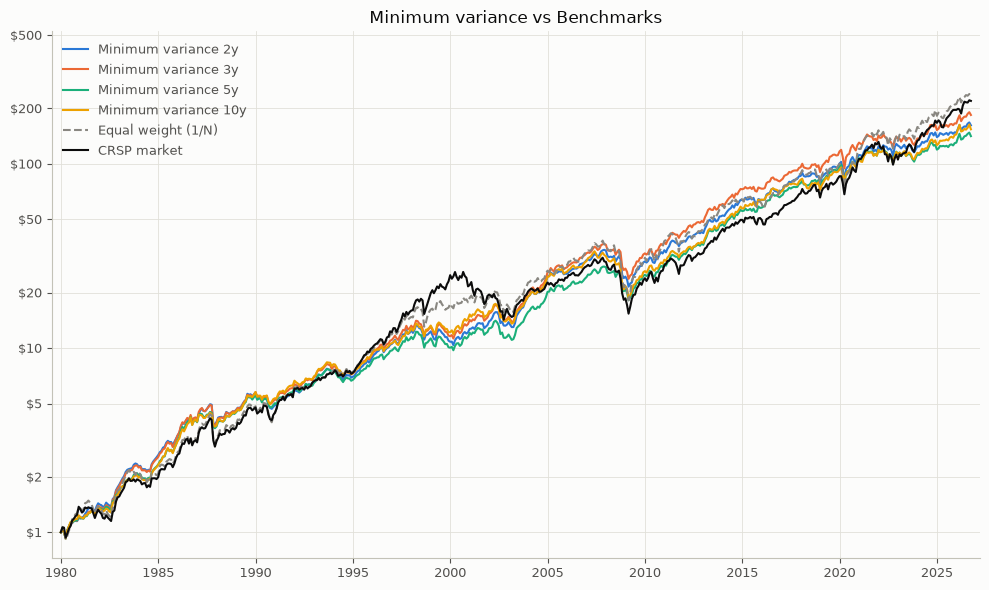

In [6]:
plot_wealth(returns, "MinVar", FIGURES / "wealth_min_variance.png");

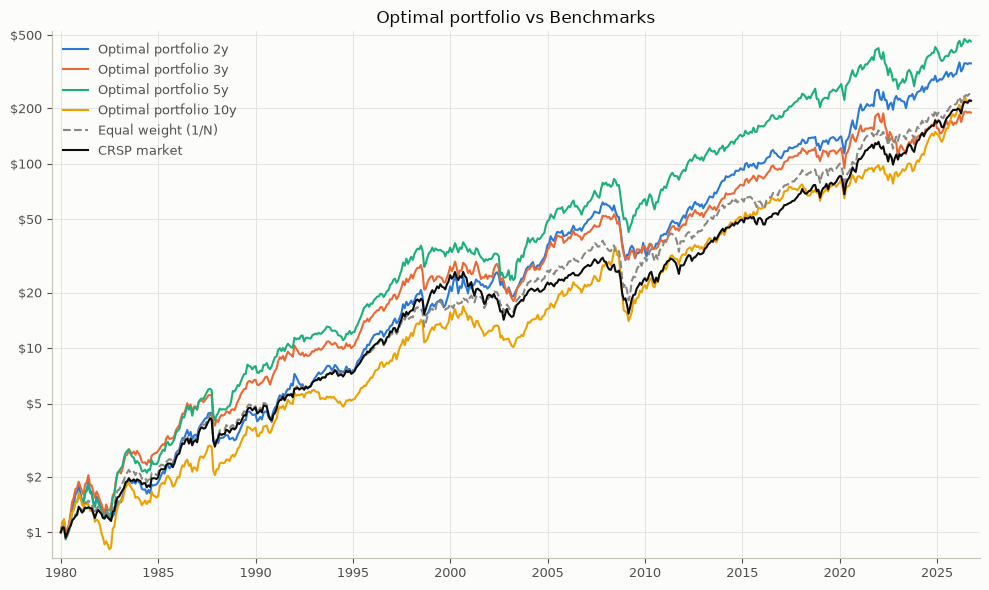

In [7]:
plot_wealth(returns, "Optimal", FIGURES / "wealth_optimal.png");

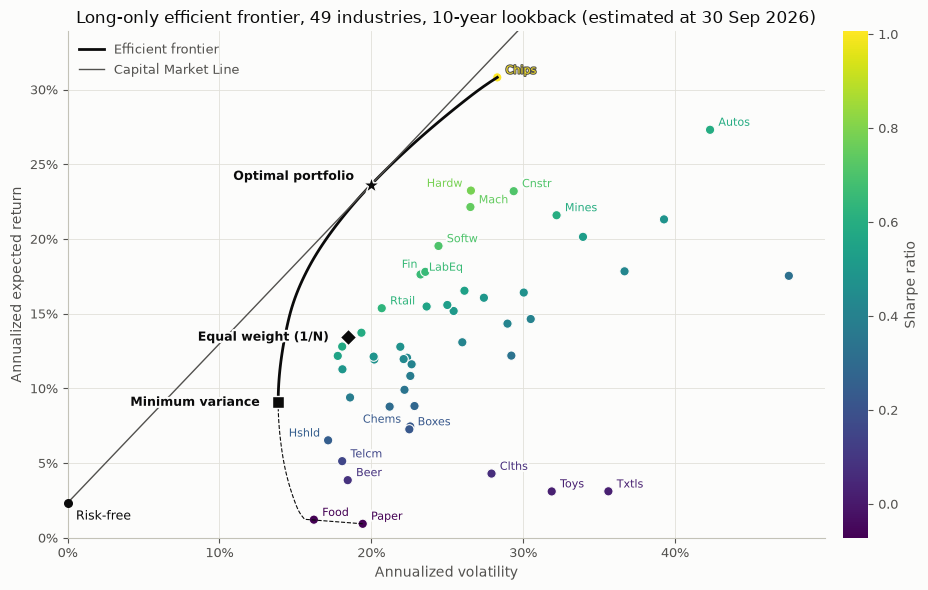

In [8]:
plot_frontier(daily, monthly, rf, rebalance_dates, path=FIGURES / "efficient_frontier.png");